# UTS GRAF SAINS DATA

analisis data retailrocket menggunakan python dan neo4j

## 2.1 wrangling dan eda

### 2.1.1 penentuan periode data

dataset retailrocket berisi data interaksi dari mei sampai september 2015. untuk tugas ini, data dibagi menjadi dua periode: p1 (training) pada 21 mei - 7 juni 2015 dan p2 (testing) pada 8 - 14 juni 2015. tanggal yang dipakai menggunakan waktu utc.

In [1]:
import pandas as pd

df = pd.read_csv("data/events.csv")

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

print("jumlah data:", len(df))
print("tanggal awal:", df["datetime"].min())
print("tanggal akhir:", df["datetime"].max())
print("\njenis interaksi:")
print(df["event"].value_counts())

jumlah data: 2756101
tanggal awal: 2015-05-03 03:00:04.384000+00:00
tanggal akhir: 2015-09-18 02:59:47.788000+00:00

jenis interaksi:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [2]:
p1_start = pd.Timestamp("2015-05-21", tz="UTC")
p1_end = pd.Timestamp("2015-06-08", tz="UTC")

p2_start = pd.Timestamp("2015-06-08", tz="UTC")
p2_end = pd.Timestamp("2015-06-15", tz="UTC")

df_p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

df_p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

users_p1 = set(df_p1["visitorid"])
users_p2 = set(df_p2["visitorid"])

print("jumlah interaksi P1:", len(df_p1))
print("jumlah interaksi P2:", len(df_p2))
print("user unik P1:", len(users_p1))
print("user unik P2:", len(users_p2))
print("user yang muncul di kedua periode:", len(users_p1 & users_p2))

jumlah interaksi P1: 364659
jumlah interaksi P2: 131852
user unik P1: 194915
user unik P2: 73177
user yang muncul di kedua periode: 5154


### 2.1.2 filtering data berdasarkan timestamp

data dibagi berdasarkan kolom timestamp yang diubah dulu ke waktu utc. p1 berisi data 21 mei - 7 juni 2015, sedangkan p2 berisi data 8 - 14 juni 2015. dari filtering diperoleh 364.659 interaksi untuk p1 dan 131.852 interaksi untuk p2. hasilnya disimpan sebagai dua file csv agar bisa dipakai lagi pada tahap berikutnya.

In [3]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

df_p1.to_csv(
    output_dir / "retailrocket_P1.csv",
    index=False
)

df_p2.to_csv(
    output_dir / "retailrocket_P2.csv",
    index=False
)

print("filtering dan penyimpanan CSV")
print("P1 training:", len(df_p1), "baris")
print("P2 testing :", len(df_p2), "baris")

print("\nfile output:")
print(output_dir / "retailrocket_P1.csv")
print(output_dir / "retailrocket_P2.csv")

filtering dan penyimpanan CSV
P1 training: 364659 baris
P2 testing : 131852 baris

file output:
output\retailrocket_P1.csv
output\retailrocket_P2.csv


In [4]:
cek_p1 = pd.read_csv("output/retailrocket_P1.csv")
cek_p2 = pd.read_csv("output/retailrocket_P2.csv")

print("P1:", cek_p1.shape)
print("P2:", cek_p2.shape)

assert len(cek_p1) == 364659
assert len(cek_p2) == 131852

print("jumlah data sesuai hasil filtering")
display(cek_p1.head())
display(cek_p2.head())

P1: (364659, 6)
P2: (131852, 6)
jumlah data sesuai hasil filtering


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433733372135,1268871,view,426550,NaN,2015-06-08 03:16:12.135000+00:00
1,1433732162877,1404274,view,323450,NaN,2015-06-08 02:56:02.877000+00:00
2,1433735119506,279808,view,465051,NaN,2015-06-08 03:45:19.506000+00:00
3,1433735999484,570716,view,117075,NaN,2015-06-08 03:59:59.484000+00:00
4,1433732165364,653349,view,320160,NaN,2015-06-08 02:56:05.364000+00:00


### 2.1.3 komposisi subgraph

bagian ini menghitung jumlah node Visitor, node Item, dan interaksi untuk masing-masing periode menggunakan python api neo4j. data dibatasi berdasarkan waktu p1 dan p2.

In [5]:
from neo4j import GraphDatabase
from getpass import getpass

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(uri, auth=(user, password))
driver.verify_connectivity()

print("Neo4j terhubung!")

Neo4j terhubung!


In [6]:
query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_time
  AND r.timestamp < $end_time
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN count(DISTINCT v) AS jumlah_visitor,
       count(DISTINCT i) AS jumlah_item,
       count(r) AS jumlah_interaksi
"""

periode = {
    "P1 Training": (p1_start, p1_end),
    "P2 Testing": (p2_start, p2_end)
}

hasil = []

with driver.session(database="neo4j") as session:
    for nama, (awal, akhir) in periode.items():
        record = session.run(
            query,
            start_time=int(awal.timestamp() * 1000),
            end_time=int(akhir.timestamp() * 1000)
        ).single()

        hasil.append({
            "Periode": nama,
            "Visitor": record["jumlah_visitor"],
            "Item": record["jumlah_item"],
            "Interaksi": record["jumlah_interaksi"]
        })

hasil_subgraph = pd.DataFrame(hasil)
display(hasil_subgraph)

,Periode,Visitor,Item,Interaksi
0,P1 Training,194915,88029,364659
1,P2 Testing,73177,48782,131852


dari query neo4j, p1 memiliki 194.915 node visitor dan 88.029 node item, dengan 364.659 interaksi. pada p2 terdapat 73.177 node visitor dan 48.782 node item, dengan 131.852 interaksi. jumlah data p1 lebih banyak karena rentang waktunya 18 hari, sedangkan p2 hanya 7 hari.

query MATCH mencari relasi antara visitor dan item, lalu WHERE membatasi timestamp sesuai periode. count(DISTINCT v) dan count(DISTINCT i) menghitung node unik, sedangkan count(r) menghitung jumlah interaksi. p1 digunakan untuk membangun rekomendasi dan p2 digunakan saat evaluasi.

### 2.1.4 VSM user

data p1 dibentuk menjadi matriks user-item. barisnya menunjukkan visitor dan kolomnya menunjukkan item. nilai 1 berarti ada interaksi, sementara nilai 0 berarti tidak ada interaksi yang tercatat. matriks disimpan dalam bentuk sparse matrix karena sebagian besar nilainya 0.

In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix

data_user = df_p1[["visitorid", "itemid"]].drop_duplicates()

user_codes, user_ids = pd.factorize(
    data_user["visitorid"], sort=True
)

item_codes, item_ids = pd.factorize(
    data_user["itemid"], sort=True
)

X_user = csr_matrix(
    (
        np.ones(len(data_user), dtype=np.uint8),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("shape VSM user-item:", X_user.shape)
print("jumlah user:", X_user.shape[0])
print("jumlah item:", X_user.shape[1])
print("jumlah interaksi unik:", X_user.nnz)

sparsity = 1 - (
    X_user.nnz / (X_user.shape[0] * X_user.shape[1])
)

print(f"sparsity: {sparsity:.6%}")

shape VSM user-item: (194915, 88029)
jumlah user: 194915
jumlah item: 88029
jumlah interaksi unik: 285428
sparsity: 99.998336%


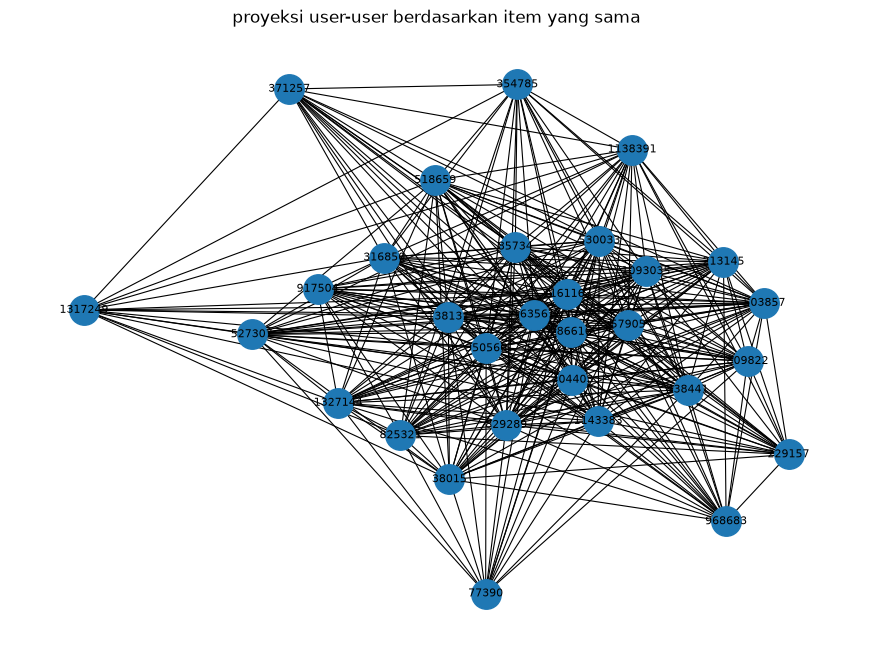

jumlah node sampel: 30
jumlah edge sampel: 375


In [8]:
from itertools import combinations
from collections import defaultdict

aktivitas_user = data_user.groupby("visitorid")["itemid"].nunique()

sample_users = (
    aktivitas_user[aktivitas_user >= 2]
    .sort_values(ascending=False)
    .head(30)
    .index
)

sample_data = data_user[
    data_user["visitorid"].isin(sample_users)
]

item_to_users = defaultdict(set)

for row in sample_data.itertuples(index=False):
    item_to_users[row.itemid].add(row.visitorid)

G_user = nx.Graph()
G_user.add_nodes_from(sample_users.tolist())

for users in item_to_users.values():
    for u1, u2 in combinations(sorted(users), 2):
        if G_user.has_edge(u1, u2):
            G_user[u1][u2]["weight"] += 1
        else:
            G_user.add_edge(u1, u2, weight=1)

plt.figure(figsize=(11, 8))

pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    node_size=450,
    font_size=8,
    with_labels=True,
    width=0.8
)

plt.title("proyeksi user-user berdasarkan item yang sama")
plt.axis("off")
plt.show()

print("jumlah node sampel:", G_user.number_of_nodes())
print("jumlah edge sampel:", G_user.number_of_edges())

matriks user-item berukuran (194915, 88029) dengan 285.428 pasangan interaksi unik. sparsity mencapai 99,998336%, jadi hampir semua posisi matriks bernilai 0. sparse matrix dipakai supaya tidak perlu menyimpan seluruh nilai 0 tersebut.

untuk visualisasi, dipilih 30 user teraktif. pada graf networkx terbentuk 375 edge. graf sampel ini cukup padat karena banyak user mengakses item yang sama. tetapi hasilnya hanya untuk 30 user yang dipilih, bukan seluruh user p1.

### 2.1.5 vsm item

vsm item menggunakan data p1 yang sama, tetapi posisi baris dan kolom matriks dibalik. setiap baris adalah item dan setiap kolom adalah user. proyeksi item-item digunakan untuk melihat produk yang diakses oleh user yang sama.

In [9]:
X_item = X_user.T.tocsr()

jumlah_item, jumlah_user = X_item.shape

sparsity_item = 1 - (
    X_item.nnz / (jumlah_item * jumlah_user)
)

print("shape VSM item-user:", X_item.shape)
print("jumlah item:", jumlah_item)
print("jumlah user:", jumlah_user)
print("interaksi unik:", X_item.nnz)
print(f"sparsity: {sparsity_item:.6%}")


shape VSM item-user: (88029, 194915)
jumlah item: 88029
jumlah user: 194915
interaksi unik: 285428
sparsity: 99.998336%


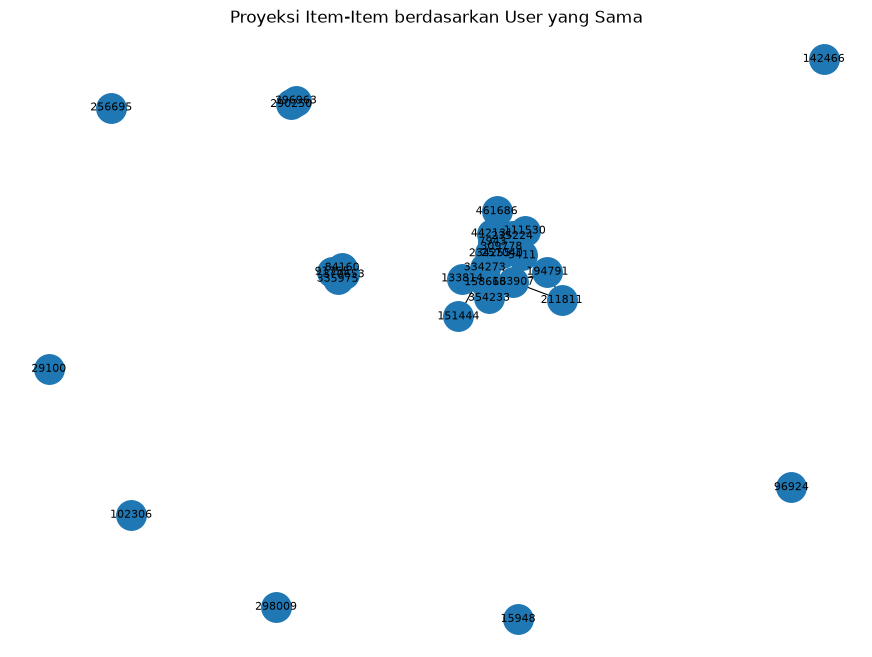

jumlah node sampel: 30
jumlah edge sampel: 60
density: 0.1379


In [10]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict
from itertools import combinations

aktivitas_item = data_user.groupby("itemid")["visitorid"].nunique()

sample_items = (
    aktivitas_item.sort_values(ascending=False)
    .head(30)
    .index
)

sample_data_item = data_user[
    data_user["itemid"].isin(sample_items)
]

user_to_items = defaultdict(set)

for row in sample_data_item.itertuples(index=False):
    user_to_items[row.visitorid].add(row.itemid)

G_item = nx.Graph()
G_item.add_nodes_from(sample_items.tolist())

for items in user_to_items.values():
    for i1, i2 in combinations(sorted(items), 2):
        if G_item.has_edge(i1, i2):
            G_item[i1][i2]["weight"] += 1
        else:
            G_item.add_edge(i1, i2, weight=1)

plt.figure(figsize=(11, 8))

pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    node_size=450,
    font_size=8,
    with_labels=True,
    width=0.8
)

plt.title("Proyeksi Item-Item berdasarkan User yang Sama")
plt.axis("off")
plt.show()

print("jumlah node sampel:", G_item.number_of_nodes())
print("jumlah edge sampel:", G_item.number_of_edges())
print("density:", round(nx.density(G_item), 4))


matriks item-user berukuran (88029, 194915), dengan 285.428 pasangan interaksi unik dan sparsity 99,998336%. nilainya sama seperti vsm user karena matriks hanya ditranspose.

graf networkx memakai 30 item yang paling banyak diakses. hasilnya 60 edge dengan density 0,1379. beberapa item saling terhubung dan ada juga yang berdiri sendiri. jumlah edge lebih sedikit daripada sampel user-user, tetapi keduanya menggunakan sampel yang berbeda sehingga belum cukup untuk menyimpulkan efisiensi seluruh graf.

### 2.1.6 perbandingan proyeksi user-user dan item-item

proyeksi user-user memiliki 194.915 node, sedangkan item-item memiliki 88.029 node. keduanya berasal dari 285.428 pasangan interaksi unik. pada sampel 30 node, user-user menghasilkan 375 edge (density 0,8621), sedangkan item-item menghasilkan 60 edge (density 0,1379).

untuk tahap similarity dipilih item-item karena jumlah node yang dibandingkan lebih sedikit dan hasilnya bisa dipakai untuk mencari produk yang mirip. pilihan ini berdasarkan eksplorasi ukuran dan graf sampel, belum berdasarkan pengukuran waktu komputasi langsung.

In [11]:
perbandingan = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah Node": [X_user.shape[0], X_item.shape[0]],
    "Dimensi Vektor": [X_user.shape[1], X_item.shape[1]],
    "Interaksi Unik": [X_user.nnz, X_item.nnz],
    "Edge Sampel": [
        G_user.number_of_edges(),
        G_item.number_of_edges()
    ],
    "Density Sampel": [
        nx.density(G_user),
        nx.density(G_item)
    ]
})

display(perbandingan)

print("proyeksi yang dipilih untuk nomor 7: item-item")


,Proyeksi,Jumlah Node,Dimensi Vektor,Interaksi Unik,Edge Sampel,Density Sampel
0,User-User,194915,88029,285428,375,0.862069
1,Item-Item,88029,194915,285428,60,0.137931


proyeksi yang dipilih untuk nomor 7: item-item


### 2.1.7 perhitungan similarity item-item

cosine similarity dihitung menggunakan matriks item-user dari p1. item dengan jumlah user terbanyak dipilih sebagai acuan, kemudian dicari lima item dengan similarity tertinggi. nilainya disimpan ke neo4j sebagai relasi `SIMILAR_TO`.

In [12]:
import numpy as np
import pandas as pd

jumlah_user_item = np.asarray(
    X_item.getnnz(axis=1)
)

idx_acuan = int(np.argmax(jumlah_user_item))
item_acuan = int(item_ids[idx_acuan])

vektor_acuan = X_item.getrow(idx_acuan).astype(np.float64)
matriks_item = X_item.astype(np.float64)

dot_product = (matriks_item @ vektor_acuan.T).tocoo()

norm_item = np.sqrt(
    np.asarray(matriks_item.multiply(matriks_item).sum(axis=1)).ravel()
)

norm_acuan = norm_item[idx_acuan]

kandidat = dot_product.row
nilai_dot = dot_product.data

valid = (
    (kandidat != idx_acuan) &
    (norm_item[kandidat] > 0)
)

kandidat = kandidat[valid]

similarity = (
    nilai_dot[valid] /
    (norm_item[kandidat] * norm_acuan)
)

hasil_similarity = pd.DataFrame({
    "item_acuan": item_acuan,
    "item_mirip": np.asarray(item_ids[kandidat], dtype=int),
    "similarity": similarity
})

hasil_similarity = (
    hasil_similarity[hasil_similarity["similarity"] > 0]
    .sort_values(
        ["similarity", "item_mirip"],
        ascending=[False, True]
    )
    .head(5)
    .reset_index(drop=True)
)

print("item acuan:", item_acuan)
print("jumlah user pada item acuan:", jumlah_user_item[idx_acuan])

display(hasil_similarity)

item acuan: 5411
jumlah user pada item acuan: 356


,item_acuan,item_mirip,similarity
0,5411,33030,0.167833
1,5411,33956,0.107098
2,5411,358234,0.080128
3,5411,375492,0.065424
4,5411,89143,0.061199


In [13]:
query_simpan = """
UNWIND $data AS row
MATCH (a:Item {itemId: row.item_acuan})
MATCH (b:Item {itemId: row.item_mirip})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.similarity,
    r.periode = 'P1'
RETURN count(r) AS jumlah_relasi
"""

data_similarity = hasil_similarity.to_dict(orient="records")

with driver.session(database="neo4j") as session:
    result = session.run(
        query_simpan,
        data=data_similarity
    ).single()

    print("jumlah relasi similarity:", result["jumlah_relasi"])

jumlah relasi similarity: 5


#### 2.1.7(a) lima item dengan similarity tertinggi

item acuan yang dipilih adalah 5411. hasil perhitungan python dan query neo4j menunjukkan item 33030 (0,167833), 33956 (0,107098), 358234 (0,080128), 375492 (0,065424), dan 89143 (0,061199). nilainya cukup kecil karena tidak banyak user yang mengakses kedua item yang dibandingkan.

query cypher yang dijalankan di neo4j:

MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)

WHERE r.periode = 'P1'

RETURN a.itemId AS item_acuan,

        b.itemId AS item_mirip,

       r.similarity AS similarity

ORDER BY similarity DESC, item_mirip ASC

LIMIT 5;



#### 2.1.7(b) menambahkan similarity ke graf

hasil similarity dari python disimpan sebagai lima relasi SIMILAR_TO. item 5411 terhubung dengan lima item lainnya. properti similarity pada relasi berisi nilai cosine similarity.

query untuk melihat graf di neo4j:

MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)

WHERE r.periode = 'P1'

RETURN a, r, b;


hasil query berupa 6 node item dan 5 relasi SIMILAR_TO. 

### 2.1.8 graf sebelum dan sesudah similarity

untuk membandingkan hasilnya, graf awal dilihat dari interaksi visitor-item pada p1, lalu dibandingkan dengan graf item-item yang memiliki relasi SIMILAR_TO. kedua query hanya menampilkan bagian graf, bukan menghapus data aslinya.

**sebelum similarity** - query neo4j:

MATCH (v:Visitor)-[r]->(i:Item {itemId: 5411})

WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']

  AND r.timestamp >= 1432166400000

  AND r.timestamp < 1433721600000
  
RETURN v, r, i

LIMIT 20;



**sesudah similarity** - query neo4j:

MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)

WHERE r.periode = 'P1'

RETURN a, r, b;



pada graf sebelum similarity, item 5411 terlihat terhubung dengan 20 visitor lewat 19 relasi VIEWED dan 1 relasi ADDED_TO_CART. sesudah similarity, item 5411 terhubung dengan lima item lain lewat SIMILAR_TO. hasil kedua query memperlihatkan jenis hubungan yang berbeda: interaksi visitor-item dan kemiripan antar-item. data interaksi aslinya tetap ada.

## 2.2 analytics

### 2.2.1(a) rekomendasi dengan item-based knn

model menggunakan interaksi p1 sebagai data training. user dipilih secara acak dari pengunjung yang punya minimal lima item unik di p1 dan juga muncul pada p2. daftar kandidat diurutkan, kemudian diacak dengan seed 42 supaya hasil pemilihannya bisa diulang.

untuk tiap item yang pernah diakses user, dicari lima item terdekat menggunakan cosine similarity (k = 5). skor kandidat dijumlahkan, lalu diurutkan. item yang sudah diakses pada p1 tidak direkomendasikan lagi. kalau user pertama tidak menghasilkan sedikitnya lima rekomendasi dengan similarity positif, pemilihan dilanjutkan ke urutan acak berikutnya memakai p1 saja. ini dilakukan supaya evaluasi tetap menggunakan lima rekomendasi, tanpa melihat item apa yang relevan di p2.

In [14]:
from sklearn.preprocessing import normalize
import numpy as np
import pandas as pd

k = 5
seed = 42

jumlah_item_per_user = df_p1.groupby("visitorid")["itemid"].nunique()
users_p1 = set(df_p1["visitorid"].unique())
users_p2 = set(df_p2["visitorid"].unique())

kandidat_user = np.array(sorted(
    uid for uid in (users_p1 & users_p2)
    if jumlah_item_per_user.loc[uid] >= 5
), dtype=np.int64)

rng = np.random.default_rng(seed)
urutan_acak = rng.permutation(kandidat_user)

item_to_index = {int(item): idx for idx, item in enumerate(item_ids)}
X_item_normal = normalize(X_item.astype(np.float32), norm="l2", axis=1)

print("random seed:", seed)
print("jumlah kandidat user:", len(kandidat_user))
print("jumlah tetangga knn:", k)

random seed: 42
jumlah kandidat user: 623
jumlah tetangga knn: 5


In [15]:
def tetangga_item(item_id, k=5):
    idx = item_to_index[int(item_id)]
    nilai = (X_item_normal @ X_item_normal.getrow(idx).T).tocoo()

    pasangan = [
        (int(item_ids[i]), float(s))
        for i, s in zip(nilai.row, nilai.data)
        if i != idx and s > 0
    ]
    pasangan.sort(key=lambda x: (-x[1], x[0]))
    return pasangan[:k]


def rekomendasi_knn(riwayat, k=5):
    skor = {}
    for item_id in sorted(riwayat):
        for item_lain, similarity in tetangga_item(item_id, k):
            if item_lain not in riwayat:
                skor[item_lain] = skor.get(item_lain, 0.0) + similarity

    hasil = sorted(skor.items(), key=lambda x: (-x[1], x[0]))
    return pd.DataFrame(hasil, columns=["itemid", "skor"])


riwayat_per_user = df_p1.groupby("visitorid")["itemid"].agg(lambda s: set(s.astype(int)))

user_terpilih = None
hasil_knn = None
jumlah_percobaan = 0

for uid in urutan_acak:
    uid = int(uid)
    riwayat = riwayat_per_user.loc[uid]
    kandidat = rekomendasi_knn(riwayat, k=k)
    jumlah_percobaan += 1

    if len(kandidat) >= 5:
        user_terpilih = uid
        train_items_user = riwayat
        hasil_knn = kandidat
        break

if user_terpilih is None:
    raise RuntimeError("tidak ada user dengan lima kandidat KNN positif pada P1")

test_items_user = set(
    df_p2.loc[df_p2["visitorid"] == user_terpilih, "itemid"].astype(int)
)

print("user terpilih:", user_terpilih)
print("urutan percobaan:", jumlah_percobaan)
print("jumlah item unik p1:", len(train_items_user))
print("jumlah item unik p2:", len(test_items_user))
print("jumlah kandidat rekomendasi:", len(hasil_knn))
display(hasil_knn.head(5))

user terpilih: 1244913
urutan percobaan: 1
jumlah item unik p1: 5
jumlah item unik p2: 1
jumlah kandidat rekomendasi: 14


,itemid,skor
0,29580,1.393578
1,67341,0.500000
2,235823,0.447214
3,200657,0.353553
4,302755,0.333333


### 2.2.1(b) tiga item yang direkomendasikan untuk k = 5

model mengambil lima tetangga untuk setiap item dalam riwayat user. skor rekomendasi berasal dari penjumlahan cosine similarity. tiga item dengan skor tertinggi ditampilkan sebagai item yang diiklankan. untuk evaluasi @5, digunakan lima item teratas, bukan hanya tiga.

In [16]:
top5 = hasil_knn.head(5).copy()
top3 = top5.head(3).copy()

print("user terpilih:", user_terpilih)
print("3 item yang diiklankan:")
display(top3)

print("5 item untuk evaluasi:")
display(top5)

user terpilih: 1244913
3 item yang diiklankan:


,itemid,skor
0,29580,1.393578
1,67341,0.500000
2,235823,0.447214


5 item untuk evaluasi:


,itemid,skor
0,29580,1.393578
1,67341,0.500000
2,235823,0.447214
3,200657,0.353553
4,302755,0.333333


### 2.2.2 evaluasi hit@5 dan ndcg@5

hasil rekomendasi dari p1 dibandingkan dengan item yang diakses user pada p2. item yang sudah ada di riwayat p1 tidak dihitung sebagai target baru pada p2. hit@5 bernilai 1 kalau ada minimal satu item relevan dalam lima rekomendasi, dan 0 kalau tidak ada. ndcg@5 memperhitungkan posisi item relevan pada urutan rekomendasi, dengan relevansi biner.

In [17]:
recommended_5 = top5["itemid"].astype(int).tolist()
relevan_p2 = test_items_user - train_items_user

relevansi = [int(item in relevan_p2) for item in recommended_5]
hit_at_5 = int(any(relevansi))

dcg_at_5 = sum(
    rel / np.log2(pos + 2)
    for pos, rel in enumerate(relevansi)
)

jumlah_relevan_ideal = min(5, len(relevan_p2))
idcg_at_5 = sum(
    1 / np.log2(pos + 2)
    for pos in range(jumlah_relevan_ideal)
)

ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("user terpilih:", user_terpilih)
print("item relevan p2 yang belum dilihat di p1:", sorted(relevan_p2))
print("top 5 rekomendasi:", recommended_5)
print("relevansi top 5:", relevansi)
print("hit@5:", hit_at_5)
print("ndcg@5:", round(ndcg_at_5, 6))

user terpilih: 1244913
item relevan p2 yang belum dilihat di p1: [363909]
top 5 rekomendasi: [29580, 67341, 235823, 200657, 302755]
relevansi top 5: [0, 0, 0, 0, 0]
hit@5: 0
ndcg@5: 0.0


nilai hit@5 dan ndcg@5 diambil dari output cell di atas. hasil untuk satu user tidak mewakili performa model pada semua user. seluruh perhitungan similarity dan rekomendasi memakai p1; p2 hanya digunakan untuk memilih user yang kembali aktif dan menghitung evaluasi.